In [ ]:
# EDA for M2 Submission

In [42]:
import json, glob, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
PLOTS = Path("plots")
PLOTS.mkdir(exist_ok=True)

DATA = "../data/processed"
REC = f"{DATA}/tfrecords-224"
MIN_COUNT = 10
plt.rcParams["figure.dpi"] = 110

def save(fig, name):
    fig.savefig(PLOTS / f"{name}.png", dpi=150, bbox_inches="tight")

In [37]:
train = json.load(open(f"{DATA}/counts_train.json"))
test = json.load(open(f"{DATA}/counts_test.json")) #these two json files are created in build_tfrecords.py

df = (pd.DataFrame({"train": train, "test": test}).fillna(0).astype(int)
      .assign(total=lambda d: d.train + d.test)
      .sort_values("train", ascending=False))

df["train_pct"] = df.train / df.train.sum() * 100
df["kept"] = df.train > MIN_COUNT
df.head(10)

,train,test,total,train_pct,kept
US,124365,23875,148240,24.8730,True
DE,27993,1204,29197,5.5986,True
FR,24646,2047,26693,4.9292,True
RU,22372,14984,37356,4.4744,True
JP,21296,2128,23424,4.2592,True
AU,16620,11052,27672,3.3240,True
BR,14368,10425,24793,2.8736,True
GB,14216,1491,15707,2.8432,True
SE,13466,2105,15571,2.6932,True
IT,11854,1508,13362,2.3708,True


In [40]:
print(f"Total Countries: {len(df)}")
print(f"Average number of images per country: {df.train.mean()}")
print(f"Total Countries after filtering by MIN_COUNT: {df.kept.sum()}")
print(f"Train images: {df.train.sum():,}")
print(f"Test images: {df.test.sum():,}")
print(f"Images retained after cutoff: {df[df.kept].train.sum() / df.train.sum():}")
print(f"Majority-class baseline (kept): "
      f"{df[df.kept].test.max() / df[df.kept].test.sum():.1%}  ({df[df.kept].train.idxmax()})")

Total Countries: 225
Average number of images per country: 2222.222222222222
Total Countries after filtering by MIN_COUNT: 188
Train images: 500,000
Test images: 210,122
Images retained after cutoff: 0.999804
Majority-class baseline (kept): 11.5%  (US)


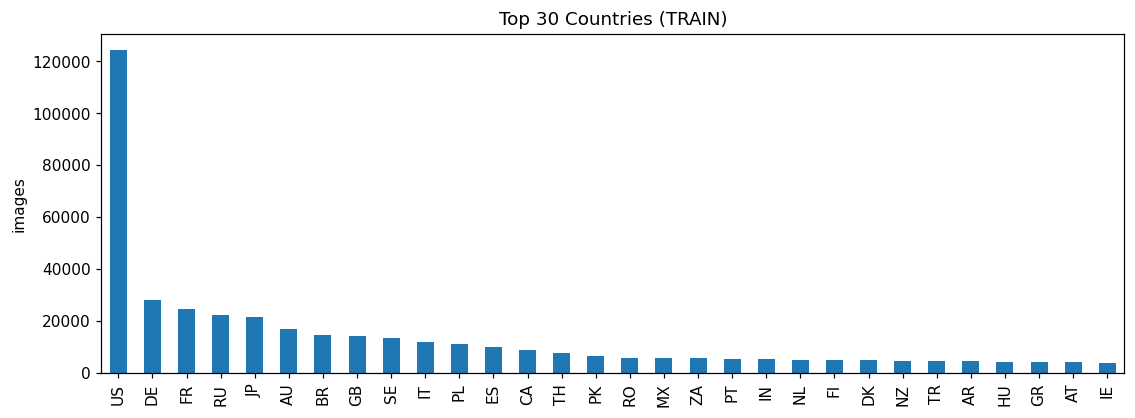

In [43]:
#top 30 countries
fig, ax = plt.subplots(figsize = (12,4))
df.train.head(30).plot.bar(ax=ax)
ax.set(title = "Top 30 Countries (TRAIN)", ylabel = "images")
save(fig, "Top 30 Countries (TRAIN)")
plt.show()

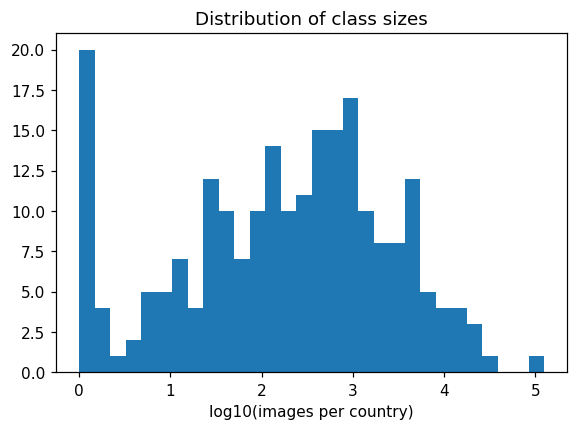

In [44]:
#histogram of per-country counts
fig, ax = plt.subplots(figsize=(6,4))
ax.hist(np.log10(df.train.clip(lower=1)), bins=30)
ax.set(xlabel="log10(images per country)", title="Distribution of class sizes")
save(fig, "Distribution of class sizes")
plt.show()

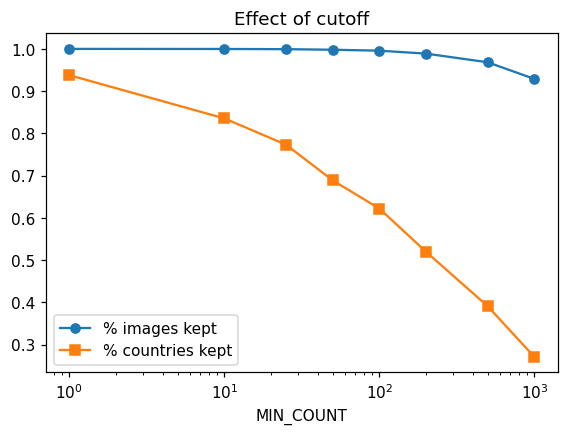

In [45]:
#data kept vs. threshold
fig, ax = plt.subplots(figsize=(6,4))
thresholds = np.unique(np.r_[1, 10, 25, 50, 100, 200, 500, 1000])
ax.plot(thresholds, [df[df.train >= t].train.sum() / df.train.sum() for t in thresholds], "o-", label="% images kept")
ax.plot(thresholds, [(df.train >= t).mean() for t in thresholds], "s-", label="% countries kept")
ax.set(xscale="log", xlabel="MIN_COUNT", title="Effect of cutoff"); ax.legend()
save(fig, "Effect of Cutoff")
plt.show()